# Выбор локации для скважины

Компания «ГлавРосГосНефть» предоставила данные разведовательной команды в трёх регионах: в каждом 10 000 месторождений, где измерили качество нефти и объём её запасов. Наша цель - рассчитать прибыльность регионов для бурения скважин на основании предоставленных данных и выбрать регион для дальнейшей разработки.
Проанализировать возможную прибыль и риски техникой *Bootstrap.*

Шаги для выбора локации:

- В избранном регионе ищут месторождения, для каждого определяют значения признаков;
- Строят модель и оценивают объём запасов;
- Выбирают месторождения с самым высокими оценками значений. Количество месторождений зависит от бюджета компании и стоимости разработки одной скважины;
- Прибыль равна суммарной прибыли отобранных месторождений.

## Загрузка и подготовка данных

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.utils import shuffle
import warnings

warnings.filterwarnings('ignore')

In [2]:
#Зафиксируем random_state
RANDOM_STATE = 42

In [16]:
# бюджет на разработку скважин в регионе (10 милн тыс. руб), т.к. расчет в тыс. руб.
budget = 10_000_000 
# при разведке региона исследуют 500 точек
chosen_points = 500 
# из которых с помощью машинного обучения выбирали 200 лучших
best_points = 200
# цена за баррель нефти
price_per_barrel = 450

In [3]:
# откроем датасет либо локально, либо из интернета
try:
    df0 = pd.read_csv('/datasets/geo_data_0.csv')
    df1 = pd.read_csv('/datasets/geo_data_1.csv')
    df2 = pd.read_csv('/datasets/geo_data_2.csv')
except:
    df0 = pd.read_csv('https://code.s3.yandex.net/datasets/geo_data_0.csv')
    df1 = pd.read_csv('https://code.s3.yandex.net/datasets/geo_data_1.csv')
    df2 = pd.read_csv('https://code.s3.yandex.net/datasets/geo_data_2.csv')

In [4]:
#Посмотрим информацию по датасетам
display(df0.info())
display(df1.info())
display(df2.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


None

Построим тепловые карты датасетов и посмотрим на корреляции данных

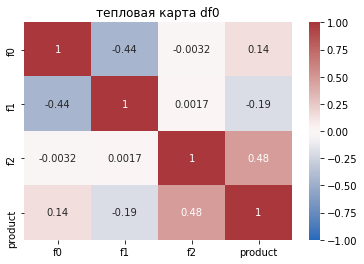

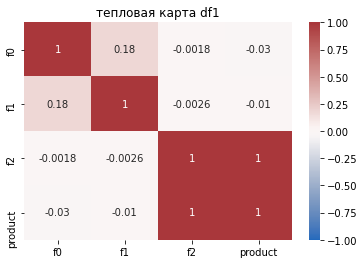

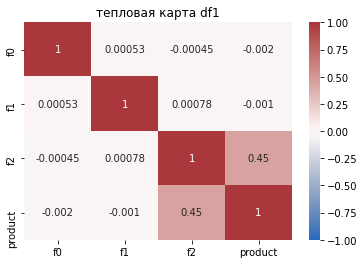

In [5]:
fig, ax = plt.subplots()
heatmap = sns.heatmap(df0.corr(), vmin=-1, vmax=1, annot=True, cmap='vlag')
heatmap.set_title('тепловая карта df0')
plt.show()

heatmap = sns.heatmap(df1.corr(), vmin=-1, vmax=1, annot=True, cmap='vlag')
heatmap.set_title('тепловая карта df1')
plt.show()

fig, ax = plt.subplots()
heatmap = sns.heatmap(df2.corr(), vmin=-1, vmax=1, annot=True, cmap='vlag')
heatmap.set_title('тепловая карта df1')
plt.show()

Второй датасет вызывает вопросы, данные по f2 сильно коррелируют с значениями product, посмотрим подробнее:

In [6]:
display(df0.describe())
display(df1.describe())
display(df2.describe())

,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.500419,0.250143,2.502647,92.500000
std,0.871832,0.504433,3.248248,44.288691
min,-1.408605,-0.848218,-12.088328,0.000000
25%,-0.072580,-0.200881,0.287748,56.497507
50%,0.502360,0.250252,2.515969,91.849972
75%,1.073581,0.700646,4.715088,128.564089
max,2.362331,1.343769,16.003790,185.364347


,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.141296,-4.796579,2.494541,68.825000
std,8.965932,5.119872,1.703572,45.944423
min,-31.609576,-26.358598,-0.018144,0.000000
25%,-6.298551,-8.267985,1.000021,26.953261
50%,1.153055,-4.813172,2.011479,57.085625
75%,8.621015,-1.332816,3.999904,107.813044
max,29.421755,18.734063,5.019721,137.945408


,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.002023,-0.002081,2.495128,95.000000
std,1.732045,1.730417,3.473445,44.749921
min,-8.760004,-7.084020,-11.970335,0.000000
25%,-1.162288,-1.174820,0.130359,59.450441
50%,0.009424,-0.009482,2.484236,94.925613
75%,1.158535,1.163678,4.858794,130.595027
max,7.238262,7.844801,16.739402,190.029838


Построим гистограммы по столбцу product в каждом регионе:

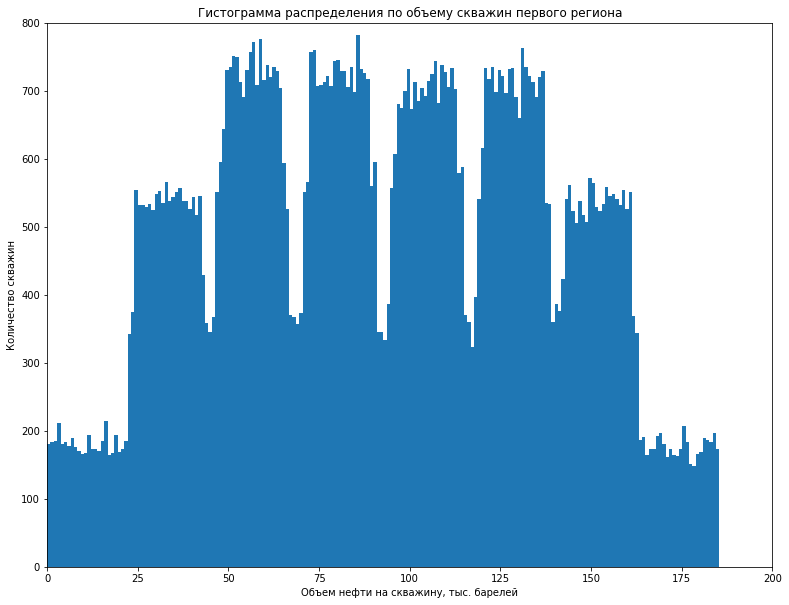

In [7]:
plt.figure(figsize=[13,10])
plt.hist(df0['product'], bins=200)

plt.xlim([0,200])
plt.ylim([0,800])
plt.xlabel("Объем нефти на скважину, тыс. барелей")
plt.ylabel("Количество скважин")

plt.title("Гистограмма распределения по объему скважин первого региона")
plt.show()

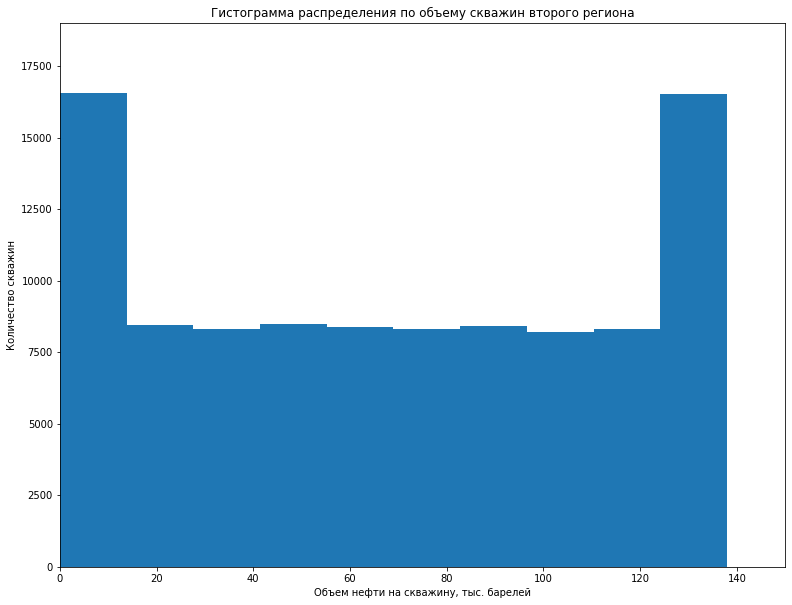

In [8]:
plt.figure(figsize=[13,10])
plt.hist(df1['product'], bins=10)

plt.xlim([0,150])
plt.ylim([0,19000])
plt.xlabel("Объем нефти на скважину, тыс. барелей")
plt.ylabel("Количество скважин")

plt.title("Гистограмма распределения по объему скважин второго региона")
plt.show()

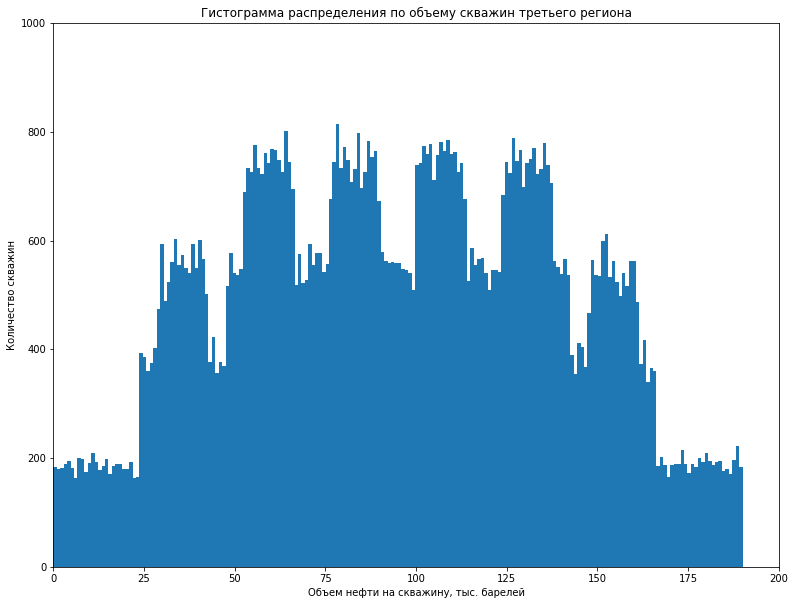

In [9]:
plt.figure(figsize=[13,10])
plt.hist(df2['product'], bins=200)

plt.xlim([0,200])
plt.ylim([0,1000])
plt.xlabel("Объем нефти на скважину, тыс. барелей")
plt.ylabel("Количество скважин")

plt.title("Гистограмма распределения по объему скважин третьего региона")
plt.show()

Данные во втором датасете похожи на придуманные.

**Подготовим данные**

Удалим неинформативный признак из каждого датафрейма - столбец id.

In [10]:
df0 = df0.drop(['id'], axis=1)
df1 = df1.drop(['id'], axis=1)
df2 = df2.drop(['id'], axis=1)

**Вывод**
Данные готовы к обучению.

В таблицах отсутствуют пропуски. Все данные, кроме колонки id имеют численное значение. Столбец id не несет информации для обучения модели.
К первому и третьему датасэту вопросов нет, а вот ко второму датасэту стоит отнестись с вниманием - скорей всего данные заполнялись не по факту.


## Обучение и проверка модели

In [11]:
# выделим признаки и целевой признак
features_0 = df0.drop('product', axis=1)
target_0 = df0['product']

features_1 = df1.drop('product', axis=1)
target_1 = df1['product']

features_2 = df2.drop('product', axis=1)
target_2 = df2['product']

In [12]:
#Разделим обучающую и валидационную выборку
features_train_0, features_valid_0, target_train_0, target_valid_0 = train_test_split(
    features_0, target_0, test_size=0.25, random_state=RANDOM_STATE)

features_train_1, features_valid_1, target_train_1, target_valid_1 = train_test_split(
    features_1, target_1, test_size=0.25, random_state=RANDOM_STATE)

features_train_2, features_valid_2, target_train_2, target_valid_2 = train_test_split(
    features_2, target_2, test_size=0.25, random_state=RANDOM_STATE)

print(f'Данные 0 разбиты в соотношении: '
      f'{len(features_train_0) / len(features_0):.2f}:'
      f'{len(features_valid_0) / len(features_0):.2f}')
print(f'Данные 1 разбиты в соотношении: '
      f'{len(features_train_1) / len(features_1):.2f}:'
      f'{len(features_valid_1) / len(features_1):.2f}')
print(f'Данные 2 разбиты в соотношении: '
      f'{len(features_train_2) / len(features_2):.2f}:'
      f'{len(features_valid_2) / len(features_2):.2f}')


Данные 0 разбиты в соотношении: 0.75:0.25
Данные 1 разбиты в соотношении: 0.75:0.25
Данные 2 разбиты в соотношении: 0.75:0.25


In [13]:
#стандартизируем признаки
numeric = ['f0', 'f1', 'f2']
scaler = StandardScaler()

scaler.fit(features_train_0[numeric])
features_train_0[numeric] = scaler.transform(features_train_0[numeric])
features_valid_0[numeric] = scaler.transform(features_valid_0[numeric])

scaler.fit(features_train_1[numeric])
features_train_1[numeric] = scaler.transform(features_train_1[numeric])
features_valid_1[numeric] = scaler.transform(features_valid_1[numeric])

scaler.fit(features_train_2[numeric])
features_train_2[numeric] = scaler.transform(features_train_2[numeric])
features_valid_2[numeric] = scaler.transform(features_valid_2[numeric])

**Обучим модель и сделаем предсказания на валидационной выборке**

In [14]:
def oil_reserves(features_train, target_train, features_valid, target_valid):
    model = LinearRegression().fit(features_train, target_train)
    predicted = model.predict(features_valid)
    rmse = (mean_squared_error(target_valid, predicted)) ** 0.5
    print(f'Средний запас предсказанного сырья в регионе: {predicted.mean():.2f} тыс. баррелей')
    print(f'RMSE модели {rmse:.2f}')
    return predicted

In [15]:
print('Регион 1')
predicted_target_0 = oil_reserves(features_train_0, target_train_0, features_valid_0, target_valid_0)
print()

print('Регион 2')
predicted_target_1 = oil_reserves(features_train_1, target_train_1, features_valid_1, target_valid_1)
print()

print('Регион 3')
predicted_target_2 = oil_reserves(features_train_2, target_train_2, features_valid_2, target_valid_2)

Регион 1
Средний запас предсказанного сырья в регионе: 92.40 тыс. баррелей
RMSE модели 37.76

Регион 2
Средний запас предсказанного сырья в регионе: 68.71 тыс. баррелей
RMSE модели 0.89

Регион 3
Средний запас предсказанного сырья в регионе: 94.77 тыс. баррелей
RMSE модели 40.15


**Вывод**
Лучшее предсказание модели во втором регионе (RMSE - 0.89).

Вероятной причиной этого скорей всего является то, что датасэт по второму региону был заполнен фиктивными (округленными) значениями.

## Подготовка к расчёту прибыли

**Рассчет достаточного объёма нефти для безубыточной разработки новой скважины**

Посчитаем требования к прибыли и объемам:

In [17]:
average_profit_per_point = budget / best_points
print('Средняя прибыль на скважину должна составлять:',
      f'{average_profit_per_point:.2f}, тыс. руб.')

average_barrels_per_point = average_profit_per_point  / price_per_barrel
print('Средний объем нефти на скважину должен составлять:',
      f'{average_barrels_per_point:.2f}, тыс. барелей')

average_barrels_per_region = budget / price_per_barrel
print('Средний объем нефти на регион должен составлять:',
      f'{average_barrels_per_region:.2f}, тыс. барелей')

Средняя прибыль на скважину должна составлять: 50000.00, тыс. руб.
Средний объем нефти на скважину должен составлять: 111.11, тыс. барелей
Средний объем нефти на регион должен составлять: 22222.22, тыс. барелей


Сравним полученный объём сырья со средним запасом в каждом регионе:

In [18]:
print('Фактический средний объем нефти на скважину в первом регионе:', df0['product'].mean())
print('Дефицит объема нефти на точку в регионе 1:', df0['product'].mean()-average_barrels_per_point)
print()
print('Фактический средний объем нефти на скважину во втором регионе:', df1['product'].mean())
print('Дефицит объема нефти на точку в регионе 2:', df1['product'].mean()-average_barrels_per_point)
print()
print('Фактический средний объем нефти на скважину в третьем регионе:', df2['product'].mean())
print('Дефицит объема нефти на точку в регионе 3:', df2['product'].mean()-average_barrels_per_point)

Фактический средний объем нефти на скважину в первом регионе: 92.50000000000001
Дефицит объема нефти на точку в регионе 1: -18.6111111111111

Фактический средний объем нефти на скважину во втором регионе: 68.82500000000002
Дефицит объема нефти на точку в регионе 2: -42.2861111111111

Фактический средний объем нефти на скважину в третьем регионе: 95.00000000000004
Дефицит объема нефти на точку в регионе 3: -16.11111111111107


**Функция для расчёта прибыли**

Напишем функцию для расчёта прибыли по выбранным скважинам и предсказаниям модели, но сначала приведем данные к типу Series:

In [19]:
# приведем данные к типу Series
target_valid_0 = target_valid_0.reset_index(drop=True)
predicted_target_0 = pd.Series(predicted_target_0)

target_valid_1 = target_valid_1.reset_index(drop=True)
predicted_target_1 = pd.Series(predicted_target_1)

target_valid_2 = target_valid_2.reset_index(drop=True)
predicted_target_2 = pd.Series(predicted_target_2)

In [20]:
# напишем функцию для расчёта прибыли
def oil_profit_calculation(target, predictions, count):
    predictions_sorted = predictions.sort_values(ascending=False)
    selected = target[predictions_sorted.index][:count]
    return price_per_barrel * selected.sum() - budget

In [21]:
print('Прибыль по первому региону:',
      f'{oil_profit_calculation(target_valid_0, predicted_target_0, best_points):.2f}, тыс. рублей')
print('Прибыль по второму региону:',
      f'{oil_profit_calculation(target_valid_1, predicted_target_1, best_points):.2f}, тыс. рублей')
print('Прибыль по третьему региону:',
      f'{oil_profit_calculation(target_valid_2, predicted_target_2, best_points):.2f}, тыс. рублей')

Прибыль по первому региону: 3359141.11, тыс. рублей
Прибыль по второму региону: 2415086.70, тыс. рублей
Прибыль по третьему региону: 2598571.76, тыс. рублей


**Вывод**
Для безубыточной разработки новой скважины средний объем нефти на скважину должен составлять 111.11, тыс. барелей.

При этом шанс окупить затраты у второго региона меньше чем у остольных: средний дефицит объема нефти на скважину в этом регионе составляет -42.29 тыс. барелей.

Наибольшая прогнозируемая прибыль у первого региона: 3359141.11, тыс. рублей.


## Расчёт прибыли и рисков 

Bootstrap с 1000 выборок

In [22]:
state = np.random.RandomState(8800)
def bootstrap(target, probs):
    values=[]
    loss = 0
    for i in range(1000):
        target_sample = target.sample(n=chosen_points, replace=True, random_state=state)
        probs_sample = probs[target_sample.index]
        profit = oil_profit_calculation(target, probs_sample, best_points)
        if profit < 0:
            loss +=1
        values.append(profit)
    
    values = pd.Series(values)
    lower = values.quantile(0.025)
    upper = values.quantile(0.975)
    average = values.mean()
    #risk = loss / values.count()
    risk = (values < 0).mean()
    return average, lower, upper, risk

**Cредняя прибыль, 95%-й доверительный интервал и риск убытков**

Применим функцию bootstrap и выведем среднюю прибыль, доверительный интервал и риск убытков для каждого региона:

In [23]:
average_0, lower_0, upper_0, risk_0 = bootstrap(target_valid_0, predicted_target_0)
print('Средняя прибыль в первом регионе составляет {:.2f} тыс.руб.'.format(average_0))
print('95%-й доверительный интервал первого региона от {:.2f} до {:.2f} тыс.руб.'
      .format(lower_0, upper_0))
print('Процент риска в первом регионе составляет {:.2%}\n'.format(risk_0))

average_1, lower_1, upper_1, risk_1 = bootstrap(target_valid_1, predicted_target_1)
print('Средняя прибыль во втором регионе составляет {:.2f} тыс.руб.'.format(average_1))
print('95%-й доверительный интервал второго региона от {:.2f} до {:.2f} тыс.руб.'
      .format(lower_1, upper_1))
print('Процент риска во втором регионе составляет {:.2%}\n'.format(risk_1))

average_2, lower_2, upper_2, risk_2 = bootstrap(target_valid_2, predicted_target_2)
print('Средняя прибыль в третьем регионе составляет {:.2f} тыс.руб.'.format(average_2))
print('95%-й доверительный интервал третьего региона от {:.2f} до {:.2f} тыс.руб.'
      .format(lower_2, upper_2))
print('Процент риска в третьем регионе составляет {:.2%}'.format(risk_2))

Средняя прибыль в первом регионе составляет 389674.05 тыс.руб.
95%-й доверительный интервал первого региона от -150520.96 до 929037.08 тыс.руб.
Процент риска в первом регионе составляет 7.00%

Средняя прибыль во втором регионе составляет 450168.03 тыс.руб.
95%-й доверительный интервал второго региона от 68092.62 до 846548.41 тыс.руб.
Процент риска во втором регионе составляет 1.00%

Средняя прибыль в третьем регионе составляет 385920.41 тыс.руб.
95%-й доверительный интервал третьего региона от -166485.47 до 904647.10 тыс.руб.
Процент риска в третьем регионе составляет 8.40%


**Вывод**
По результатам подсчета рисков и прибыли лидером стал второй регион: средняя прибыль составит 450168.03 тыс.руб, при этом риск минимальный, всего 1.00%.

Первый и третий регионы имеют достаточно высокий процент риска: 7.00% и 8.40% соответственно, что не удовлетворяет условию поставленной задачи (риски не должны превышать 2.50%).


**Выводы**
По результатам знакомства с датасетами заметна фиктивность (или искуственное округление) значений во втором регионе.

После обучения модели выяснилось, что лучшая среднеквадратическая ошибка во втором регионе - 0.89, при этом фактический средний объем нефти на скважину в регионе оказался самым низким: всего 68.71 тыс. баррелей из прогнозируемого минимума в 111 тыс. баррелей.

Опираясь на технику Bootstrap единственным регионом для рекомендации разработки скважин оказался второй регион.
По доверительному интервалу можно сказать, что даже при не удачном выборе скважины - разработка окупится.

## Чек-лист готовности проекта

Поставьте 'x' в выполненных пунктах. Далее нажмите Shift+Enter.

- [x]  Jupyter Notebook открыт
- [ ]  Весь код выполняется без ошибок
- [ ]  Ячейки с кодом расположены в порядке исполнения
- [ ]  Выполнен шаг 1: данные подготовлены
- [ ]  Выполнен шаг 2: модели обучены и проверены
    - [ ]  Данные корректно разбиты на обучающую и валидационную выборки
    - [ ]  Модели обучены, предсказания сделаны
    - [ ]  Предсказания и правильные ответы на валидационной выборке сохранены
    - [ ]  На экране напечатаны результаты
    - [ ]  Сделаны выводы
- [ ]  Выполнен шаг 3: проведена подготовка к расчёту прибыли
    - [ ]  Для всех ключевых значений созданы константы Python
    - [ ]  Посчитано минимальное среднее количество продукта в месторождениях региона, достаточное для разработки
    - [ ]  По предыдущему пункту сделаны выводы
    - [ ]  Написана функция расчёта прибыли
- [ ]  Выполнен шаг 4: посчитаны риски и прибыль
    - [ ]  Проведена процедура *Bootstrap*
    - [ ]  Все параметры бутстрепа соответствуют условию
    - [ ]  Найдены все нужные величины
    - [ ]  Предложен регион для разработки месторождения
    - [ ]  Выбор региона обоснован

<div style="border:solid Chocolate 2px; padding: 40px">

**Общий вывод по проекту**

Александр, спасибо за твой проект! У тебя замечательная работа! В тебе виден будущий профессионал своего дела :) 
    
Кратко пройдусь по впечатлениям. 

**Отмечу отдельные положительные моменты проекта🙂**:
 
* Прекрасное владение инструментами обработки данных!
* Умелое проведение машинного обучения!
* Потрясающие навыки использования функций для повышения эффективности работы!
* Все этапы работы проделаны очень осмысленно! Каждый шаг снабжен пояснениями и выводами!
* Работа имеет четкую структуру и выполнена аккуратно, проверять - одно удовольствие!

    
**На что стоит обратить внимание🤓**:
   
* В работе все еще присутсвует достаточно много повторяющегося кода, которые можно было бы зациклить.
* Оставила для тебя также некоторые рекомендаций по улучшению оформления и эффективности кода.
    
    
В целом работа готова к тому, чтобы быть принятой, но верну на всякий случай, если вдруг у тебя есть вопросы или желание разобрать что-то подробнее :)


**Желаю удачи!**😉
    
<img src="https://99px.ru/sstorage/86/2015/12/image_86271215043043632690.gif" />